# Spherical harmonics and the spectrum (Phase 3, step 5)

**Questions.** How do spherical harmonic decompositions relate to the Laplace–Beltrami spectrum? Can real lesions be mapped to a sphere? Are harmonic features more reliable than eigenvalues, and do they carry signal beyond volume?

How to rerun: [`docs/reproductions/lb-spherical-harmonics.md`](../docs/reproductions/lb-spherical-harmonics.md). Earlier steps: [`lb-roundness.ipynb`](lb-roundness.ipynb), [`lb-stability.ipynb`](lb-stability.ipynb).

## 1. Theory

**One framework, two views.** Spherical harmonics $Y_{\ell m}$ are the Laplace–Beltrami eigenfunctions of the round sphere, with eigenvalue $\ell(\ell+1)$ and multiplicity $2\ell+1$. A lesion's own eigenfunctions are the same object on its own surface. So the spectrum describes the surface *intrinsically*, while a harmonic expansion describes how it sits in space, *extrinsically*: the isometric dent in `lb-features-3d.ipynb` leaves the spectrum alone and changes the harmonics.

**The map needs genus 0.** Harmonics live on the sphere, so a surface must be mapped to it first, which uniformisation allows exactly for genus 0. We use conformalized mean curvature flow [Kazhdan et al. 2012], then balance the map by Möbius transformations so the surface's area has centre of mass at the origin. **This is the map in Hersch's proof.** Its coordinates $F$ satisfy $\lambda_1\text{Area}\le\sum_i\int|\nabla F_i|^2=8\pi$ when $F$ is exactly conformal, so the map can be tested against that inequality on every lesion.

**The expansion.** $x(\omega)=\sum_{\ell m}c_{\ell m}Y_{\ell m}(\omega)$ for each coordinate, with $c_{\ell m}\in\mathbb{R}^3$. The power $P_\ell=\sum_m|c_{\ell m}|^2$ is unchanged by rotating the shape or the parametrisation, because both act orthogonally. Dividing by $\text{Area}/4\pi$ removes scale.

**Proposition (where a lobe appears).** For radius $1+\varepsilon f$ with $f$ of degree $d$, the coordinates are $x=(1+\varepsilon f)\,\omega$, and $\omega$ has degree 1. A product of degrees $d$ and 1 lies in degrees $d\pm1$, so to first order the lobe's power sits at $\ell=d\pm1$. **Two views of one lobe:** the harmonic power shows it at $d\pm1$, and the spectrum's level splitting first shows it at $\ell=d/2$. Verified in Section 3.

**Conformal is not area-preserving.** Classic SPHARM [Brechbühler et al. 1995] uses an area-preserving map, where degree 1 gives an ellipsoid's axes. A conformal map compresses long parts, so its degree-1 axes only order shapes, and thin parts need high degrees. We chose it because it connects to Hersch and to the spectrum, and it is cheap and robust.

## 2. Implementation details

| Choice | Ours | Why |
|---|---|---|
| Surface | Size-matched as in `lb-stability.ipynb` | No size leak |
| Topology correction | Raise smoothing by 1.5× until closed and genus 0 | Simple; it also removes real detail, so the steps are stored |
| Sphere map | cMCF, 40 steps, step 0.05; Möbius balance by source vertex area | Kazhdan et al. 2012; settings chosen on test shapes |
| Coefficients | Weighted least squares, weights = sphere vertex area, degree 15 | Handles unequal sampling |
| Noise | 0.25, 0.5, 1 mm, 2 draws, model of `lb-stability.ipynb` | Comparable with eigenvalues, though fewer draws |
| Real error | Zhou 2021 masks on Test patches, geometry only; weights read only | As the previous step |
| Labels | Train+Validation only | Test stays clean |

## 3. Verification

In [1]:
import sys; sys.path.insert(0, "..")
import numpy as np, pandas as pd, matplotlib.pyplot as plt, trimesh
from matplotlib.colors import LinearSegmentedColormap
from scipy.stats import spearmanr
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.metrics import roc_auc_score
from sklearn.model_selection import StratifiedKFold, cross_val_predict
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from abus_classification.features.shape_descriptor.shape_descriptors import compute_laplace_beltrami_operator, lb_spectrum, sphere_level_spread
from abus_classification.features.shape_descriptor.spharm import map_quality, real_harmonics, spharm_coefficients, spharm_power, sphere_map
from abus_classification.utils.mesh import draw_mesh
from test.utils_tests.features_tests.test_signature import lobed_sphere

BLUE, ORANGE, AQUA, INK, GRID = "#2a78d6", "#eb6834", "#1baf7a", "#52514e", "#e4e3df"
DIVERGING = LinearSegmentedColormap.from_list("signed", ["#104a8e", BLUE, "#dedcd6", ORANGE, "#8f3410"])
RAMP = LinearSegmentedColormap.from_list("ramp", ["#e6eef8", "#86b2e8", BLUE, "#104a8e"])
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "axes.edgecolor": INK, "axes.labelcolor": INK, "xtick.color": INK, "ytick.color": INK, "axes.grid": True, "grid.color": GRID, "font.size": 10})
stab = np.load("../results/lb-stability/sample_meshes.npz"); round_ = np.load("../results/lb-roundness/sample_meshes.npz")
def lesion(store, key): return trimesh.Trimesh(store[key + "_vertices"].astype(float), store[key + "_faces"], process=False)
LESIONS = {"Malignant, median volume": lesion(stab, "malignant_clean"), "Benign, median volume": lesion(stab, "benign_clean"), "Benign, low λ₁·Area sample": lesion(round_, "benign_q5")}
SPHERES = {k: sphere_map(m) for k, m in LESIONS.items()}

sphere = trimesh.creation.icosphere(subdivisions=6); basis = real_harmonics(sphere.vertices, 4)
L_err = np.abs(np.diag(basis.T @ (compute_laplace_beltrami_operator(sphere)[0] @ basis)) - np.concatenate([[l * (l + 1)] * (2 * l + 1) for l in range(5)])).max()
print(f"Harmonics on a fine sphere mesh: largest error in the Rayleigh quotient against l(l+1) = {L_err:.3f}")
rows = []
for d in (2, 4, 6):
    m = lobed_sphere(d, 0.05, subdivisions=5); c = spharm_coefficients(m, sphere_map(m), 8); p = spharm_power(c, 8)
    spread = sphere_level_spread(lb_spectrum(lobed_sphere(d, 0.02), 49, False))
    rows.append({"Lobe degree d": d, "Largest power, l >= 2": 2 + int(p[2:].argmax()), "Predicted, l = d ± 1": f"{d - 1}, {d + 1}", "First level split in the spectrum": 1 + int((spread > 0.25 * spread.max()).argmax()), "Predicted, d / 2": d // 2})
pd.DataFrame(rows)

Harmonics on a fine sphere mesh: largest error in the Rayleigh quotient against l(l+1) = 0.010


,Lobe degree d,"Largest power, l >= 2","Predicted, l = d ± 1",First level split in the spectrum,"Predicted, d / 2"
0,2,3,"1, 3",1,1
1,4,5,"3, 5",2,2
2,6,7,"5, 7",3,3


Both views of a single lobe land where the theory says. The figure shows the harmonics themselves, and what a lobe looks like in each view.

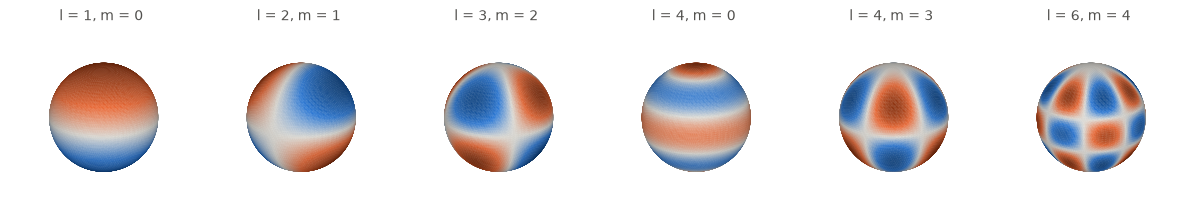

In [2]:
deg = [(1, 0), (2, 1), (3, 2), (4, 0), (4, 3), (6, 4)]; m = trimesh.creation.icosphere(subdivisions=5); y = real_harmonics(m.vertices, 6); fig = plt.figure(figsize=(12, 2.4))
for i, (l, k) in enumerate(deg):
    v = y[:, l ** 2 + l + k]; limit = np.abs(v).max(); ax = fig.add_subplot(1, 6, i + 1, projection="3d"); draw_mesh(ax, m, v, DIVERGING, -limit, limit); ax.set_title(f"l = {l}, m = {k}", fontsize=10, color=INK)
plt.tight_layout(); plt.savefig("../docs/assets/lb-3d-harmonics.png", dpi=130); plt.show()

## 4. The sphere map on real lesions

Each lesion beside its sphere map, with colour marking the original height, so you can track where each part goes. Long parts shrink into a small patch: conformal maps keep angles and give up area.

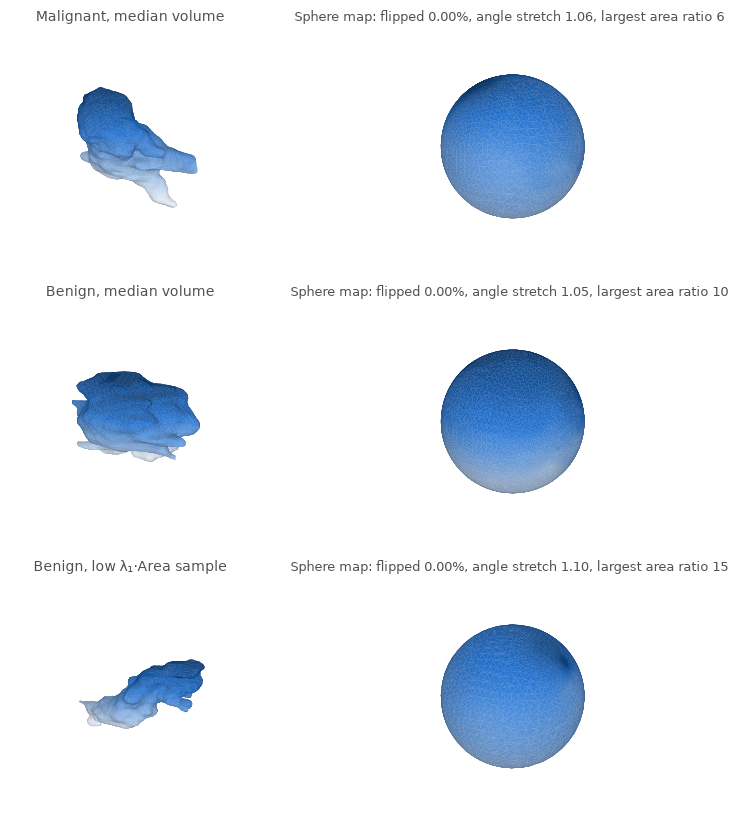

In [3]:
fig = plt.figure(figsize=(9, 8.4))
for i, (name, m) in enumerate(LESIONS.items()):
    z = m.vertices[:, 2]; limits = dict(vmin=np.percentile(z, 2), vmax=np.percentile(z, 98))
    ax = fig.add_subplot(3, 2, 2 * i + 1, projection="3d"); draw_mesh(ax, m, z, RAMP, **limits); ax.set_title(name, fontsize=10, color=INK)
    flipped, stretch, area = map_quality(m, SPHERES[name])
    ax = fig.add_subplot(3, 2, 2 * i + 2, projection="3d"); draw_mesh(ax, trimesh.Trimesh(SPHERES[name], m.faces, process=False), z, RAMP, **limits)
    ax.set_title(f"Sphere map: flipped {flipped:.2%}, angle stretch {stretch:.2f}, largest area ratio {area:.0f}", fontsize=9, color=INK)
plt.tight_layout(); plt.savefig("../docs/assets/lb-3d-spheremap.png", dpi=130); plt.show()

In [4]:
d = np.load("../results/lb-spharm/features.npz"); R = list(map(str, d["renders"]))
P, axes, err, q, area, volume, lam1, energy, steps = [d[k] for k in "power axes error quality area volume lam1 energy steps".split()]
ratio, e8 = lam1 * area / (8 * np.pi), energy / (8 * np.pi)
pd.Series({"Lesions mapped": int((~np.isnan(area[:, 0])).sum()), "Lesions needing topology correction": int((steps[:, 0] > 0).sum()), "Same, 1 mm noise, share of surfaces": (steps[:, 5:] > 0).mean(),
           "Largest flipped-triangle share": np.nanmax(q[:, 0, 0]), "Median angle stretch": np.nanmedian(q[:, 0, 1]), "Median largest area ratio": np.nanmedian(q[:, 0, 2]), "95th pct largest area ratio": np.nanpercentile(q[:, 0, 2], 95),
           "Map energy / 8π, lowest": np.nanmin(e8[:, 0]), "Map energy / 8π, median": np.nanmedian(e8[:, 0]), "Map energy / 8π, highest": np.nanmax(e8[:, 0]), "Lesions with λ₁·Area ≤ map energy": np.nanmean(ratio[:, 0] <= e8[:, 0]),
           "Median reconstruction error, degree 15, share of radius": np.nanmedian(err[:, 0, 0]), "Same, 95th pct within a lesion, median lesion": np.nanmedian(err[:, 0, 1]), "Same, worst 5% of lesions": np.nanpercentile(err[:, 0, 1], 95)}).round(4).to_frame("Clean surfaces")

,Clean surfaces
Lesions mapped,200.0000
Lesions needing topology correction,19.0000
"Same, 1 mm noise, share of surfaces",0.3225
Largest flipped-triangle share,0.0005
Median angle stretch,1.0603
Median largest area ratio,6.1766
95th pct largest area ratio,63.8398
"Map energy / 8π, lowest",0.9995
"Map energy / 8π, median",1.0016
"Map energy / 8π, highest",1.0492


The map energy is close to $8\pi$, so the maps are nearly conformal, and Hersch's chain of inequalities holds on every lesion.

## 5. What each degree adds

Real lesions rebuilt from harmonics up to each degree. Degree 1 is a rough ellipsoid. Fine detail arrives gradually, and thin parts arrive last. The last panels show the true surface, then the same surface coloured by the error left at degree 15.

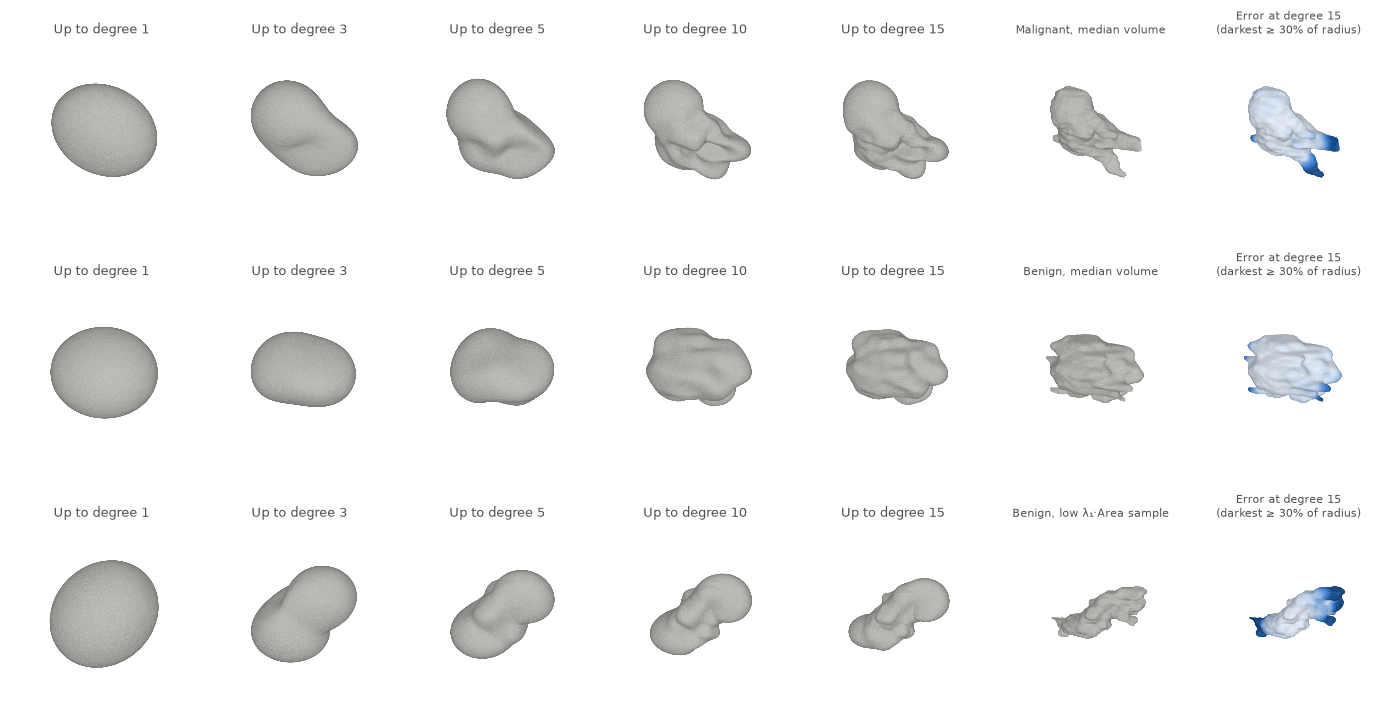

In [5]:
degrees = (1, 3, 5, 10, 15); fig = plt.figure(figsize=(14, 7.6))
for row, (name, m) in enumerate(LESIONS.items()):
    x = SPHERES[name]; c = spharm_coefficients(m, x, 15); radius = np.sqrt(m.area / (4 * np.pi)); y = real_harmonics(x, 15)
    for col, l in enumerate(degrees):
        rebuilt = trimesh.Trimesh(y[:, :(l + 1) ** 2] @ c[:(l + 1) ** 2], m.faces, process=False); ax = fig.add_subplot(3, 7, row * 7 + col + 1, projection="3d"); draw_mesh(ax, rebuilt); ax.set_title(f"Up to degree {l}", fontsize=9, color=INK)
    ax = fig.add_subplot(3, 7, row * 7 + 6, projection="3d"); draw_mesh(ax, m); ax.set_title(name, fontsize=8, color=INK)
    e = np.linalg.norm(y @ c - m.vertices, axis=1) / radius; ax = fig.add_subplot(3, 7, row * 7 + 7, projection="3d"); draw_mesh(ax, m, e, RAMP, 0, 0.3); ax.set_title("Error at degree 15\n(darkest ≥ 30% of radius)", fontsize=8, color=INK)
plt.tight_layout(); plt.savefig("../docs/assets/lb-3d-reconstruction.png", dpi=130); plt.show()

## 6. Reliability, against the spectrum

Same surfaces, same noise model. Eigenvalue ICCs use the 3 draws stored in the previous step, and harmonics use 2.

,0.25 mm,0.5 mm,1.0 mm
"Power, degree 1",0.976,0.801,0.441
"Power, degree 2",0.958,0.784,0.394
"Power, degree 3",0.960,0.829,0.534
"Power, degree 5",0.965,0.789,0.425
"Power, degree 10",0.930,0.698,0.244
"Power, degree 15",0.940,0.584,0.175
"λ·Area, k = 1",0.971,0.812,0.533
"λ·Area, k = 2",0.961,0.786,0.422
"λ·Area, k = 5",0.881,0.658,0.307
"λ·Area, k = 10",0.819,0.447,0.178


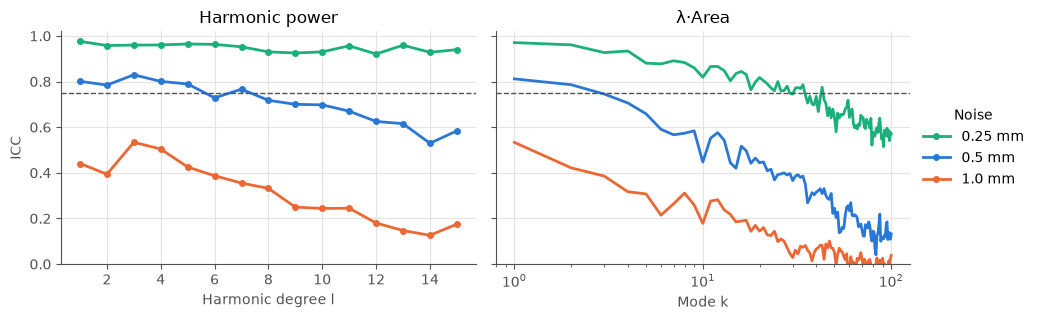

In [6]:
def icc(x):
    ok = ~np.isnan(x).any(1); x = np.log(x[ok]); m = x.shape[1]; g = x.mean(1); b = m * g.var(ddof=1); w = ((x - g[:, None]) ** 2).sum() / (x.shape[0] * (m - 1))
    return (b - w) / (b + (m - 1) * w)
amps = (0.25, 0.5, 1.0); I = {a: [0, R.index(f"noise {a} mm #0"), R.index(f"noise {a} mm #1")] for a in amps}
s = np.load("../results/lb-stability/spectra.npz"); SR = list(map(str, s["renders"])); na = s["lam"] * s["area"][..., None]; J = {a: [0] + [SR.index(f"noise {a} mm #{i}") for i in range(3)] for a in amps}
ls = (1, 2, 3, 5, 10, 15); ks = (1, 2, 5, 10, 20, 50, 100)
display(pd.DataFrame({f"{a} mm": {**{f"Power, degree {l}": icc(P[:, I[a], l]) for l in ls}, **{f"λ·Area, k = {k}": icc(na[:, J[a], k]) for k in ks}} for a in amps}).round(3).style.format(precision=3).set_caption("ICC under boundary noise"))
fig, ax = plt.subplots(1, 2, figsize=(10.5, 3.3), sharey=True)
for a, c in zip(amps, (AQUA, BLUE, ORANGE)):
    ax[0].plot(range(1, 16), [icc(P[:, I[a], l]) for l in range(1, 16)], color=c, lw=2, marker="o", ms=4, label=f"{a} mm")
    ax[1].plot(range(1, 101), [icc(na[:, J[a], k]) for k in range(1, 101)], color=c, lw=2)
ax[0].set(xlabel="Harmonic degree l", ylabel="ICC", title="Harmonic power", ylim=(0, 1.02)); ax[1].set(xlabel="Mode k", xscale="log", title="λ·Area"); ax[1].legend(*ax[0].get_legend_handles_labels(), frameon=False, title="Noise", loc="center left", bbox_to_anchor=(1, 0.5))
for a_ in ax: a_.axhline(0.75, color=INK, lw=1, ls="--")
plt.tight_layout(); plt.savefig("../docs/assets/lb-spharm-icc.png", dpi=150); plt.show()

Degree $\ell$ has $2\ell+1$ functions, so degree 15 corresponds to mode $k\approx(\ell+1)^2=256$ by resolution. So compare by resolution, not by position on these axes: degree 10 sits near mode 120, where its ICC of 0.70 at 0.5 mm stands against 0.13 at $k=100$. At low resolution the two are about equal.

### Real segmentation error

In [7]:
p = np.load("../results/lb-spharm/predicted.npz"); sp = np.load("../results/lb-stability/predicted.npz"); nap = sp["lam"] * sp["area"][..., None]
print("Missing surfaces per seed:", np.isnan(p["area"][:, 1:]).sum(0))
pair = lambda t, v: np.mean([spearmanr(t, v[:, i], nan_policy="omit")[0] for i in range(3)])
rows = {f"Power, degree {l}": pair(p["power"][:, 0, l], p["power"][:, 1:, l]) for l in ls}
rows |= {f"λ·Area, k = {k}": pair(nap[:, 0, k], nap[:, 1:, k]) for k in ks}
rows["Volume"] = pair(p["volume"][:, 0], p["volume"][:, 1:])
pd.Series(rows).round(3).to_frame("Spearman, true vs predicted, mean of seeds")

Missing surfaces per seed: [1 1 2]


,"Spearman, true vs predicted, mean of seeds"
"Power, degree 1",0.289
"Power, degree 2",0.282
"Power, degree 3",0.537
"Power, degree 5",0.532
"Power, degree 10",0.475
"Power, degree 15",0.172
"λ·Area, k = 1",0.402
"λ·Area, k = 2",0.524
"λ·Area, k = 5",0.367
"λ·Area, k = 10",0.176


## 7. Signal beyond volume

Train+Validation only. Five-fold CV repeated 20 times.

In [8]:
tv = ~d["test"]; y = d["y"][tv]; v = np.log(volume[tv, 0])[:, None]
def cv(X):
    m = make_pipeline(StandardScaler(), LogisticRegression(max_iter=3000))
    return np.mean([roc_auc_score(y, cross_val_predict(m, X, y, cv=StratifiedKFold(5, shuffle=True, random_state=s), method="decision_function")) for s in range(20)])
after = lambda X: X - LinearRegression().fit(v, X).predict(v)
L = np.log(P[tv, 0]); F = {"Power, degrees 1–3": L[:, 1:4], "Power, degrees 2–5": L[:, 2:6], "Power, degrees 1–15": L[:, 1:16], "Degree-1 axes": np.log(axes[tv, 0]), "Share of power at degree ≥ 5": np.log(P[tv, 0, 5:].sum(1) / P[tv, 0, 1:].sum(1))[:, None]}
tan = pd.read_csv("../results/lb-spectrum-content/tan_control.csv")[["SPmean", "SP90", "SP75"]].values[tv]
F["Control: Tan spiculation"] = tan
display(pd.DataFrame({n: {"Alone": cv(X), "With volume": cv(np.c_[v, X]), "After volume": cv(after(X))} for n, X in F.items()}).T.round(3).style.format(precision=3).set_caption("Cross-validated AUC"))
print(f"Volume alone: {cv(v):.3f}")
print("Spearman of each degree's power with volume:", {l: round(spearmanr(P[:, 0, l], volume[:, 0], nan_policy='omit')[0], 2) for l in ls})
print("Spearman of each degree's power with λ₁·Area:", {l: round(spearmanr(P[:, 0, l], ratio[:, 0], nan_policy='omit')[0], 2) for l in ls})

,Alone,With volume,After volume
"Power, degrees 1–3",0.571,0.715,0.544
"Power, degrees 2–5",0.576,0.706,0.558
"Power, degrees 1–15",0.522,0.664,0.502
Degree-1 axes,0.593,0.698,0.489
Share of power at degree ≥ 5,0.564,0.702,0.516
Control: Tan spiculation,0.788,0.801,0.695


Volume alone: 0.707
Spearman of each degree's power with volume: {1: np.float64(0.16), 2: np.float64(-0.15), 3: np.float64(-0.02), 5: np.float64(-0.09), 10: np.float64(-0.05), 15: np.float64(-0.08)}
Spearman of each degree's power with λ₁·Area: {1: np.float64(0.76), 2: np.float64(-0.16), 3: np.float64(-0.62), 5: np.float64(-0.53), 10: np.float64(-0.03), 15: np.float64(-0.29)}


## 8. Conclusions

- **The two views connect exactly on near-round shapes.** One lobe appears at $\ell=d\pm1$ in the harmonics and first splits level $d/2$ in the spectrum.
- **Real lesions can be mapped.** All 200 map to the sphere, 19 after topology correction, with almost no flipped triangles. The map energy is within 5% of $8\pi$ and Hersch's inequality holds on each one. The cost is area: thin parts shrink and reconstruct worst.
- **Harmonic power is more reliable than eigenvalues, and that holds on real predictions.** The advantage is at fine scales. At comparable resolution, degree 10 has ICC 0.70 at 0.5 mm against 0.13 for $k=100$, and rank 0.48 on predicted masks where eigenvalues from $k=20$ keep none. At coarse scales the two are about equal, and $\\lambda_1$ ranks better than degree 1 on predicted masks (0.40 against 0.29). Part of the advantage may come from topology correction, which smooths noisy surfaces further.
- **Reliability does not bring signal.** After volume, harmonic features score about the same as the spectrum, far below spiculation. So a stable global shape descriptor exists, but on this data global shape adds little to volume.

## 9. Protocol

All 200 lesions for geometry; 70 Test patches for predicted masks, geometry only; labels on 130 Train+Validation lesions. Malignant is positive. CPU only for features, no Kaggle kernel. Stored results: `results/lb-spharm/`. The challenge benchmark does not apply.

## 10. Open issues

- **Area-preserving maps.** These would improve thin parts and give real axes, at a higher cost.
- **Topology correction.** More smoothing also removes genuine detail. About a third of surfaces at 1 mm noise needed it, which may inflate their reliability; a topology-preserving repair would not.
- **Local descriptors.** Everything tested so far is global. This is what the remaining step, theory-driven descriptors, should try: harmonic coefficients are global, but HKS or WKS maps are local.